# Quantum teleportation

## No-cloning principle

Qubit states can't be cloned: we can't create copies of an unknown state with a general operation.

The following mathematical proof, suggested by Claude, helps to understand the why behind it.

Let's suppose that such an operation (gate) that can create a copy of a given state exists. We denote it $U$:

$$U\,|\psi\rangle|0\rangle = |\psi\rangle|\psi\rangle$$

As you can see, we have two qubits: one in the state $|\psi\rangle$ that we want to copy, and the other a blank one in the state $|0\rangle$.

This would apply to the basis vectors too:

$$U\,|0\rangle|0\rangle = |0\rangle|0\rangle$$
$$U\,|1\rangle|0\rangle = |1\rangle|1\rangle$$

And this is basically a CNOT gate, so nothing is wrong for now.

Now let's try with the state $|+\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$. Using the linearity of quantum operations, we can apply the operator on each part separately:

$$U\,|+\rangle|0\rangle = \frac{1}{\sqrt{2}}\Big[\,U|0\rangle|0\rangle + U|1\rangle|0\rangle\,\Big] = \frac{1}{\sqrt{2}}\Big(|00\rangle + |11\rangle\Big)$$

But a true copy of $|+\rangle$ would be:

$$|+\rangle|+\rangle = \frac{1}{2}\Big(|00\rangle + |01\rangle + |10\rangle + |11\rangle\Big)$$

The operation gave an entangled state (a Bell state), while the real copy is just the ordinary product of two $|+\rangle$ states, which is not entangled. These two states are different, so we get a contradiction: no operation $U$ can copy every state.

## How to achieve it then ?

Despite not having this special operator that can clone states , we can still build a circuit that can transfer state from a qubit to another , so we won't have the first qubit with the initial exact state , but wwe can garabtee that the second qubit will be in that state , a sort of quantum teleportation :)
We'll try to implement that circuit in this notebook.

## Context
We wanna transfer a quantum state from Alice to Bob , each of them got it's private qubit , and they share another common qubit to allow the communication.The teleportation protocol can be summarized as follows:

1. Alice and Bob first create an entangled Bell pair between their two qubits. They do this by applying a Hadamard and CX gate. 

2. Next, Alice applies a series of operations between the qubit with state $\vert\psi\rangle$ and her half of the Bell pair.

3. Finally, Alice measures both qubits (the one that initially contained $\vert\psi\rangle$ and the other that contained her half of the Bell pair), and reports these results to Bob.

4. Depending on what Alice says, Bob applies a couple of gates to his half of the Bell pair.

5. And voila! The state $\vert\psi\rangle$ has teleported to Bob's qubit.

In [8]:
import qiskit
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from collections import Counter
from qiskit import QuantumCircuit, transpile

In [2]:
tc = qiskit.QuantumCircuit(3, 3)
#here just as an example , we wanna tranfer a bell state from qubit 0 to qubit 2, it can be any state
#even a simple one like 0 or 1.
tc.h(0)
tc.barrier()


#we create an entagled bell state between qubit 1 and  qubit 2 
tc.h(1)
tc.cx(1, 2) 

### Step 1: Initial state

Qubit 0 is in a state $|\psi\rangle$ that we suppose unknown:

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle, \qquad |\alpha|^2 + |\beta|^2 = 1$$

Qubit 1 and qubit 2 are together in an entangled state (a Bell pair), prepared by a Hadamard gate on qubit 1 followed by a CNOT from qubit 1 to qubit 2:

$$|\Phi^+\rangle_{12} = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$

The state of the three qubits, written in the order $q_0\, q_1\, q_2$, is the tensor product of the two:

$$|\psi\rangle_0 \otimes |\Phi^+\rangle_{12} = \frac{1}{\sqrt{2}}\Big(\alpha|000\rangle + \alpha|011\rangle + \beta|100\rangle + \beta|111\rangle\Big)$$

for now nothing special

In [ ]:
# Alice will then apply a series of operation in her side (qubit 0 and qubit 1)
tc.cx(0, 1)
tc.h(0)
tc.barrier() 


### Step 2: Alice's operations on $q_0$ and $q_1$

**CNOT (control $q_0$, target $q_1$).** After applying the CX on $q_0$ and $q_1$, the state becomes:

$$|\Phi_1\rangle = \frac{1}{\sqrt{2}}\Big[\alpha|000\rangle + \alpha|011\rangle + \beta|110\rangle + \beta|101\rangle\Big]$$

We just flip $q_1$ when $q_0$ is 1: $|100\rangle \to |110\rangle$ and $|111\rangle \to |101\rangle$.

**Hadamard on $q_0$.** Next, after applying the Hadamard gate on $q_0$, we get:

$$|\Phi_2\rangle = \frac{1}{2}\Big[\alpha(|0\rangle+|1\rangle)|00\rangle + \alpha(|0\rangle+|1\rangle)|11\rangle + \beta(|0\rangle-|1\rangle)|10\rangle + \beta(|0\rangle-|1\rangle)|01\rangle\Big]$$

We just isolate $q_0$ in each term and apply the operator on its state:

$$H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}, \qquad H|1\rangle = \frac{|0\rangle - |1\rangle}{\sqrt{2}}$$

Applying it to the first qubit of each term gives a total factor $\frac{1}{\sqrt{2}} \cdot \frac{1}{\sqrt{2}} = \frac{1}{2}$.

### Step 3: Alice's measurement and Bob's correction

Now pay attention to the final state we got:

$$|\Phi_2\rangle = \frac{1}{2}\Big[\alpha|000\rangle + \alpha|100\rangle + \alpha|011\rangle + \alpha|111\rangle + \beta|010\rangle - \beta|110\rangle + \beta|001\rangle - \beta|101\rangle\Big]$$

Note that $q_0\, q_1\, q_2$ are read from left to right.

If Alice measures the qubits $q_0$ and $q_1$, they can be in one of the 4 possible outcomes: $00$, $01$, $10$, $11$.

To see what Bob's qubit becomes in each case, we regroup the terms that share the same first two symbols (Alice's qubits) and factor them out. For example, $\alpha|000\rangle + \beta|001\rangle = |00\rangle \otimes (\alpha|0\rangle + \beta|1\rangle)$. Doing this for the four outcomes gives:

$$|\Phi_2\rangle = \frac{1}{2}\Big[\,|00\rangle(\alpha|0\rangle + \beta|1\rangle) + |01\rangle(\beta|0\rangle + \alpha|1\rangle) + |10\rangle(\alpha|0\rangle - \beta|1\rangle) + |11\rangle(\alpha|1\rangle - \beta|0\rangle)\,\Big]$$

Each outcome has the same probability $\left|\frac{1}{2}\right|^2 = \frac{1}{4}$, whatever $\alpha$ and $\beta$ are. So Alice's two bits tell her nothing about $|\psi\rangle$.

If the state collapses to:

| Alice measures $(q_0\, q_1)$ | Bob's qubit becomes | In terms of $\lvert\psi\rangle$ | Correction needed |
|:---:|:---:|:---:|:---:|
| $00$ | $\alpha\lvert 0\rangle + \beta\lvert 1\rangle$ | $\lvert\psi\rangle$ | nothing |
| $01$ | $\beta\lvert 0\rangle + \alpha\lvert 1\rangle$ | $X\lvert\psi\rangle$ | apply $X$ |
| $10$ | $\alpha\lvert 0\rangle - \beta\lvert 1\rangle$ | $Z\lvert\psi\rangle$ | apply $Z$ |
| $11$ | $\alpha\lvert 1\rangle - \beta\lvert 0\rangle$ | $XZ\lvert\psi\rangle$ | apply $X$, then $Z$ |

So we need to know the outcome of Alice's measurement so that Bob can adjust the state of his qubit. Since we have only four combinations possible, it is actually easy to make the correction:

- If Alice's $q_1$ bit is 1, Bob applies an $X$ gate (bit flip) to his qubit.
- If Alice's $q_0$ bit is 1, Bob applies a $Z$ gate (phase flip) to his qubit.

In the circuit this is `cx(1, 2)` followed by `cz(0, 2)`. In a real setting, Alice sends her two classical bits to Bob, who then applies the gates conditioned on them.

Check on the $11$ case: $X$ turns $\alpha|1\rangle - \beta|0\rangle$ into $\alpha|0\rangle - \beta|1\rangle$, then $Z$ turns it into $\alpha|0\rangle + \beta|1\rangle = |\psi\rangle$. In every case, Bob ends up with exactly $|\psi\rangle$.

In [4]:
tc.measure([0, 1], [0, 1]) # results stored in classical bits 0 and 1, respectively
tc.barrier() # just a visual aid

tc.cx(1, 2)
tc.cz(0, 2)

# Step 5: Done! Measure Bob's qubit to find out what state it is in
tc.measure([2], [2])

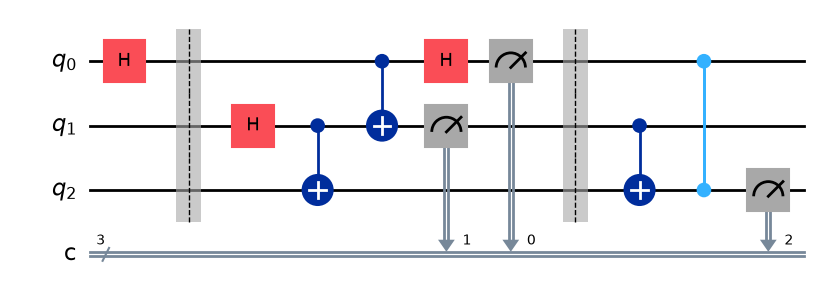

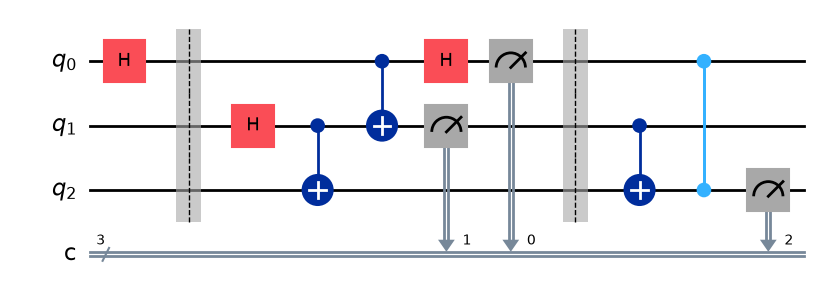

In [5]:
%matplotlib inline
tc.draw(output='mpl')

In [ ]:
#this is just an example to confirm that bob's qubit is in the same state
#as the original qubit 0, we can run the circuit and check the results
#the probability of bob's qubit being 1 should be the same as the original qubit 0 being 1
#well since we are testing with shots , the probability outcome will be close to the theoretical value but not exacly the same.
sim = AerSimulator()
shots = 4096
counts = sim.run(transpile(tc, sim), shots=shots).result().get_counts()
print("Full counts (c2 c1 c0):", counts)

# Keep only Bob's bit (the leftmost character of each key)
bob = Counter()
for bits, n in counts.items():
    bob[bits[0]] += n

print("Bob's qubit:", {"0": bob["0"], "1": bob["1"]})
print("P(Bob = 1) =", bob["1"] / shots)

Full counts (c2 c1 c0): {'000': 476, '011': 517, '111': 499, '001': 508, '010': 497, '100': 562, '110': 512, '101': 525}
Bob's qubit: {'0': 1998, '1': 2098}
P(Bob = 1) = 0.51220703125
